--- Evaluation Metrics ---
Inertia (WCSS): 102.62
Silhouette Score: 0.44



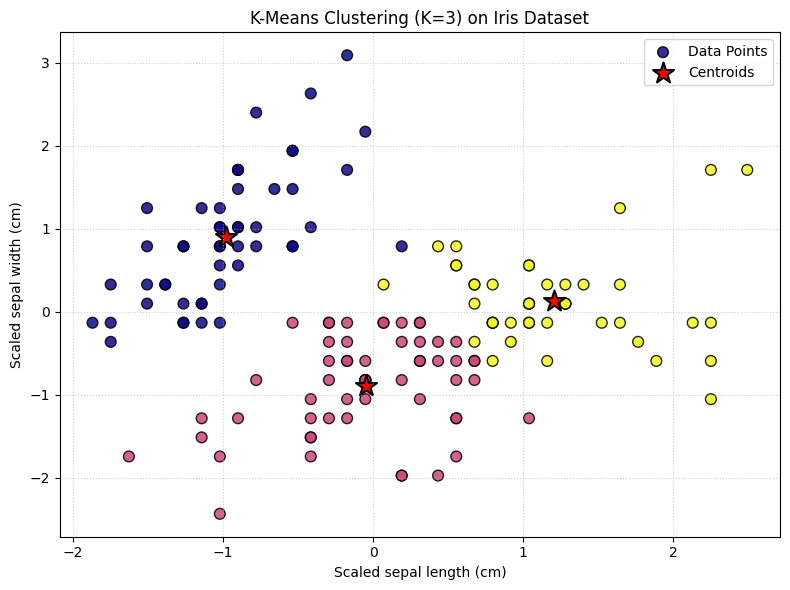

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import load_iris
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler


# 1. LOAD THE DATASET

iris = load_iris()
# Convert to DataFrame for easier inspection and handling
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# For 2D visualization purposes, we will use two primary features
features = ["sepal length (cm)", "sepal width (cm)"]
X = df[features].values

# 2. PREPROCESS DATA

# K-Means calculates Euclidean distances; features must be on the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


# 3. INITIALIZE AND FIT THE MODEL
OPTIMAL_CLUSTERS = 3

kmeans = KMeans(
    n_clusters=OPTIMAL_CLUSTERS,
    init="k-means++",  # Smart initialization to avoid poor local minima
    n_init=10,  # Number of time the algorithm will run with different seeds
    max_iter=300,
    random_state=42,
)

# Fit the model and predict cluster labels simultaneously
cluster_labels = kmeans.fit_predict(X_scaled)


# 4. EVALUATE THE CLUSTERS

# Calculate WCSS (Within-Cluster Sum of Squares / Inertia)
wcss = kmeans.inertia_

# Calculate Silhouette Score
sil_score = silhouette_score(X_scaled, cluster_labels)

print(f"--- Evaluation Metrics ---")
print(f"Inertia (WCSS): {wcss:.2f}")
print(f"Silhouette Score: {sil_score:.2f}\n")


# 5. VISUALIZE THE RESULTS
plt.figure(figsize=(8, 6))

# Plot the scaled data points colored by their cluster assignment
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=cluster_labels,
    s=60,
    cmap="plasma",
    edgecolor="k",
    alpha=0.85,
    label="Data Points",
)

# Plot the calculated centroids
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c="red",
    s=250,
    marker="*",
    edgecolor="black",
    linewidth=1.5,
    label="Centroids",
)

plt.title(f"K-Means Clustering (K={OPTIMAL_CLUSTERS}) on Iris Dataset")
plt.xlabel(f"Scaled {features[0]}")
plt.ylabel(f"Scaled {features[1]}")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()
